In [1]:
import pandas as pd
import numpy as np
import scipy
if not hasattr(scipy, "interp"):
    scipy.interp = np.interp  # restore deprecated alias

from pycaret.classification import setup, compare_models, tune_model, pull


# Load your raw dataset
df_original = pd.read_csv("data.csv")


In [2]:
df_original.columns

Index(['Date', 'Age ', 'BMI', 'Surgical Approach',
       'Pre-op visual impairment (y/n) - symptomatic complaint of visual loss',
       'Pre-op hydrocephalus (y/n)', 'Pre-op intacranial pressure symptoms',
       'Pre-op headache', 'Pre-op endocrine changes (y/n)',
       'Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional',
       'Axes disrupted', 'Tumor size', 'Tumor size.1', 'Tumor size.2',
       'Tumor volume', 'Tumor (Adamantinomatous, papillary)', 'BRAF+',
       'Location (purely intrasellar, suprasellar/sellar, suprasellar/sellar with pseudoventricular extension, suprasellar/sellar with intraventricular extension, purely intraventricular)',
       'Intraventricular extension', 'Solid, cystic, mixed',
       'Resection outcome (total, subtotal, partial)', 'Prior operation',
       'recurring tumor?', 'Recurrence after this operation',
       'Recurrence date', 'Days to recurrence',
       'Re-operation after this operation (add date)', 'Time to r

In [5]:
import pandas as pd
import numpy as np
import scipy
if not hasattr(scipy, "interp"):
    scipy.interp = np.interp  # restore deprecated alias

from pycaret.classification import setup, compare_models, tune_model, pull


# Load your raw dataset
df_original = pd.read_csv("data.csv")

# ---- Feature groups (for convenience) ----
preop_basic = [
    "Age ", "BMI", "Tumor size", "Tumor size.1", "Tumor size.2", "Tumor volume",
    "Last BMI on file",
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss",
    "Pre-op hydrocephalus (y/n)", "Pre-op intacranial pressure symptoms",
    "Pre-op headache", "Pre-op endocrine changes (y/n)",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional",
    "Intraventricular extension", "prior radiation",
]

intraop_basic = [
    "Surgical Approach",                 # raw categorical in df_original
    "Solid, cystic, mixed",              # raw categorical in df_original
    "Resection outcome (total, subtotal, partial)"
]

location_histology = [
    "Location (purely intrasellar, suprasellar/sellar, suprasellar/sellar with pseudoventricular extension, suprasellar/sellar with intraventricular extension, purely intraventricular)",
    "Tumor (Adamantinomatous, papillary)",
    "BRAF+"
]

# ---- Build 15 experiments (targets + feature sets) ----
experiments = [
    # Post-op complications
    {"target": "Recurrence after this operation",
     "features": preop_basic + ["Surgical Approach", "Resection outcome (total, subtotal, partial)", "BRAF+"]}

    # Composite endpoints (you can create these columns beforehand if desired)
    # Example creation idea (run before the loop):
    # df_original["Any complication"] = (
    #     (df_original["CSF leak"]==1) | (df_original["Transient DI"]==1) |
    #     (df_original["Permanent DI"]==1) | (df_original["Other vascular complication (need to specify)"]==1) |
    #     (df_original["Hemorrhage or hemorrhagic stroke"]==1) | (df_original["Ischemic Stroke"]==1) |
    #     (df_original["Other intracranial infection"]==1) | (df_original["Non-intracranial infection"]==1) |
    #     (df_original["Meningitis"]==1)
    # ).astype(int)

    # If you already created it, uncomment the experiment below:
    # {"target": "Any complication",
    #  "features": preop_basic + intraop_basic + location_histology},

    # Visual outcome (binary version you can precompute; multi-class needs classification setup too)
    # df_original["VisualImproved"] = (df_original[
    #   "Post-op visual improvement/stable/worse (subjective); should add something specific about visual fields if any patients have; add about visual acuity"
    # ].astype(str).str.lower().str.contains("improv")).astype(int)

    # {"target": "VisualImproved",
    #  "features": preop_basic + ["Surgical Approach"] + location_histology},

    # Two more variations to reach 15 now (without needing new columns):

]

# ---- Utility: safe compare + tune ----
def run_experiment(df, target, features, metric="AUC"):
    # Keep only columns that exist (avoid KeyError if some columns are missing)
    cols = [c for c in features + [target] if c in df.columns]
    if target not in cols:
        print(f"  [skip] Target column '{target}' not found.")
        return None, None

    # Drop rows where target is missing
    data = df[cols].copy()
    data = data[~data[target].isna()]
    if data[target].nunique() < 2:
        print(f"  [skip] Target '{target}' has <2 classes after dropping NaNs.")
        return None, None

    # PyCaret setup
    clf_setup = setup(
        data=data,
        target=target,
        session_id=42,
        fold=3,                      # safer with rare events
        fold_strategy="stratifiedkfold",
        fix_imbalance=True,          # handle class imbalance
        use_gpu=False,
        verbose=False
    )

    # Compare and enforce single estimator
    best_model = compare_models(sort=metric, n_select=1)
    # Guard: sometimes returns list
    if isinstance(best_model, list):
        best_model = best_model[0]

    if not hasattr(best_model, "fit"):
        print("  [skip] No valid estimator returned by compare_models.")
        return None, None

    # Tune
    try:
        tuned = tune_model(best_model, optimize=metric)
    except Exception as e:
        print(f"  [warn] tune_model failed for '{target}': {e}")
        tuned = best_model

    leaderboard = pull()
    return tuned, leaderboard

# ---- Run all experiments ----
all_leaderboards = {}
for exp in experiments:
    print(f"\n=== Running target: {exp['target']} ===")
    try:
        tuned, leaderboard = run_experiment(df_original, exp["target"], exp["features"], metric="AUC")
        if leaderboard is not None:
            all_leaderboards[exp["target"]] = leaderboard.copy()
            # Show the top few rows for quick inspection
            print(leaderboard.head())
    except Exception as e:
        print(f"  [error] {exp['target']}: {e}")




=== Running target: Recurrence after this operation ===


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
nb,Naive Bayes,0.7564,0.7912,0.7500,0.5738,0.6406,0.4626,0.4853,0.0400
qda,Quadratic Discriminant Analysis,0.7546,0.7727,0.4167,0.4167,0.4167,0.3167,0.3167,0.0367
lr,Logistic Regression,0.6832,0.7046,0.5833,0.3095,0.4040,0.2491,0.2880,0.0533
gbc,Gradient Boosting Classifier,0.6630,0.7000,0.5000,0.5619,0.4916,0.2556,0.2761,0.0633
ada,Ada Boost Classifier,0.7289,0.6935,0.5000,0.5333,0.5079,0.3246,0.3298,0.0600
svm,SVM - Linear Kernel,0.6593,0.6815,0.4167,0.2917,0.3333,0.1641,0.1761,0.0433
rf,Random Forest Classifier,0.7546,0.6741,0.3333,0.4444,0.3810,0.2883,0.2936,0.1067
et,Extra Trees Classifier,0.6557,0.6569,0.3333,0.5500,0.3648,0.1418,0.1813,0.1100
xgboost,Extreme Gradient Boosting,0.6593,0.6546,0.3333,0.4167,0.3611,0.1371,0.1426,0.3133
catboost,CatBoost Classifier,0.7326,0.6481,0.4167,0.6667,0.4667,0.3053,0.3443,0.8200


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.8571,0.8375,0.7500,0.7500,0.7500,0.6500,0.6500
2,0.7692,0.8611,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.7564,0.7829,0.7500,0.5738,0.6406,0.4626,0.4853
Std,0.0880,0.0944,0.2041,0.1429,0.1390,0.1996,0.2102


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).
      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.6429  0.6500  0.5000  0.4000  0.4444  0.1860  0.1886
1       0.8571  0.8375  0.7500  0.7500  0.7500  0.6500  0.6500
2       0.7692  0.8611  1.0000  0.5714  0.7273  0.5517  0.6172
Mean    0.7564  0.7829  0.7500  0.5738  0.6406  0.4626  0.4853
Std     0.0880  0.0944  0.2041  0.1429  0.1390  0.1996  0.2102


In [21]:
import pandas as pd
from pycaret.classification import setup, create_model, tune_model, finalize_model, save_model, predict_model, pull, calibrate_model

# 1) Load raw data
df_original = pd.read_csv("data.csv")

# 2) Define features for Permanent DI (pre-op + intra-op you chose)
features_permdi = [
    "Age ", "BMI", "Tumor size", "Tumor size.1", "Tumor size.2", "Tumor volume",
    "Last BMI on file",
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss",
    "Pre-op hydrocephalus (y/n)", "Pre-op intacranial pressure symptoms",
    "Pre-op headache", "Pre-op endocrine changes (y/n)",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional",
    "Intraventricular extension",
    "Surgical Approach", "Resection outcome (total, subtotal, partial)", "prior radiation", "BRAF+"
]
target = "Recurrence after this operation"

# 3) Keep only rows with target present
cols = [c for c in features_permdi + [target] if c in df_original.columns]
data = df_original[cols].dropna(subset=[target]).copy()

# 4) Pick a safe number of folds (avoid empty-class folds)
vc = data[target].value_counts()
minority = int(vc.min())
folds = max(2, min(3, minority))  # 2–3 folds depending on minority size

# 5) Setup (PyCaret will encode categoricals & impute internally)
_ = setup(
    data=data,
    target=target,
    session_id=42,
    fold=folds,
    fold_strategy="stratifiedkfold",
    fix_imbalance=True,    # helps with rare outcomes
    use_gpu=False,
    verbose=False
)

# 6) Train Ridge, then tune it (optimize F1 for class imbalance)
print("\n=== NB (base) ===")
nb = create_model("nb")
print("\n=== NB (F1 tuned) ===")
nb_f1tuned = tune_model(nb, optimize="F1")
print("\n=== NB (AUC tuned) ===")
nb_auctuned = tune_model(nb, optimize="AUC")
print("\n=== NB (Precision tuned) ===")
nb_precisiontuned = tune_model(nb, optimize="Precision")
print("\n=== NB (Recall tuned) ===")
nb_recalltuned = tune_model(nb, optimize="Recall")


print("\n=== NB (sigmoid calibrated) ===")
nb_cal_sig=calibrate_model(nb, method='sigmoid')
print("\n=== NB (isotonic calibrated) ===")
nb_cal_iso=calibrate_model(nb, method='isotonic')


# 7) Finalize on the full dataset (locks preprocessing + tuned params)
nb_final = finalize_model(nb_cal_iso)

# 8) Save the whole pipeline (preprocessing + model)
save_model(nb_final, "recurrence_nb_v1")

# 9) (optional) Get CV/holdout predictions for sanity check
preds = predict_model(nb_final)
print(preds.head())



=== NB (base) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.8571,0.8625,0.7500,0.7500,0.7500,0.6500,0.6500
2,0.7692,0.8611,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.7564,0.7912,0.7500,0.5738,0.6406,0.4626,0.4853
Std,0.0880,0.0998,0.2041,0.1429,0.1390,0.1996,0.2102



=== NB (F1 tuned) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.8571,0.8375,0.7500,0.7500,0.7500,0.6500,0.6500
2,0.7692,0.8611,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.7564,0.7829,0.7500,0.5738,0.6406,0.4626,0.4853
Std,0.0880,0.0944,0.2041,0.1429,0.1390,0.1996,0.2102


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).

=== NB (AUC tuned) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.8571,0.8375,0.7500,0.7500,0.7500,0.6500,0.6500
2,0.7692,0.8611,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.7564,0.7829,0.7500,0.5738,0.6406,0.4626,0.4853
Std,0.0880,0.0944,0.2041,0.1429,0.1390,0.1996,0.2102


... (7 outputs left out)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6750,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.9286,0.8625,0.7500,1.0000,0.8571,0.8108,0.8257
2,0.7692,0.8333,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.8040,0.7903,0.7500,0.6905,0.6948,0.5542,0.5810
Std,0.0909,0.0824,0.2041,0.2208,0.1476,0.2085,0.2161


Transformation Pipeline and Model Successfully Saved


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Naive Bayes,0.7222,0.7692,0.8000,0.5000,0.6154,0.4156,0.4438


    Age     BMI  Tumor size  Tumor size.1  Tumor size.2  Tumor volume  \
37    49    NaN         1.9           1.4           1.0      1.392772   
53    52  26.99         3.6           3.8           3.8     27.218737   
13    64  24.01         2.7           1.5           2.1      4.453204   
34    45  29.34         2.8           2.5           1.6      5.864301   
4     14  20.60         NaN           NaN           NaN           NaN   

    Last BMI on file  \
37         37.549999   
53         33.720001   
13         23.770000   
34         29.900000   
4          23.100000   

    Pre-op visual impairment (y/n) - symptomatic complaint of visual loss  \
37                                                1.0                       
53                                                1.0                       
13                                                1.0                       
34                                                1.0                       
4                              

In [ ]:
print("\n=== CatBoost (base) ===")
catboost = create_model("catboost")
print("\n=== CatBoost (F1 tuned) ===")
catboost_f1tuned = tune_model(catboost, optimize="F1")
print("\n=== CatBoost (AUC tuned) ===")
catboost_auctuned = tune_model(catboost, optimize="AUC")
print("\n=== CatBoost (Precision tuned) ===")
catboost_precisiontuned = tune_model(catboost, optimize="Precision")
print("\n=== CatBoost (Recall tuned) ===")
catboost_recalltuned = tune_model(catboost, optimize="Recall")





=== CatBoost (base) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.5250,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.7143,0.7250,0.5000,0.5000,0.5000,0.3000,0.3000
2,0.7692,0.7222,0.2500,1.0000,0.4000,0.3158,0.4330
Mean,0.7326,0.6574,0.4167,0.6667,0.4667,0.3053,0.3443
Std,0.0259,0.0936,0.1179,0.2357,0.0471,0.0074,0.0627



=== CatBoost (F1 tuned) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6500,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
2,0.9231,0.7778,0.7500,1.0000,0.8571,0.8060,0.8216
Mean,0.7601,0.6926,0.5833,0.6333,0.6005,0.4307,0.4367
Std,0.1189,0.0602,0.1179,0.2625,0.1829,0.2694,0.2759


Fitting 3 folds for each of 10 candidates, totalling 30 fits

=== CatBoost (AUC tuned) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6500,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
2,0.9231,0.7778,0.7500,1.0000,0.8571,0.8060,0.8216
Mean,0.7601,0.6926,0.5833,0.6333,0.6005,0.4307,0.4367
Std,0.1189,0.0602,0.1179,0.2625,0.1829,0.2694,0.2759


... (3 outputs left out)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6500,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
2,0.9231,0.7778,0.7500,1.0000,0.8571,0.8060,0.8216
Mean,0.7601,0.6926,0.5833,0.6333,0.6005,0.4307,0.4367
Std,0.1189,0.0602,0.1179,0.2625,0.1829,0.2694,0.2759


Fitting 3 folds for each of 10 candidates, totalling 30 fits


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7857,0.5000,0.5000,0.6667,0.5714,0.4324,0.4404
1,0.7143,0.7500,0.2500,0.5000,0.3333,0.1765,0.1936
2,0.6923,0.6667,0.0000,0.0000,0.0000,0.0000,0.0000
Mean,0.7308,0.6389,0.2500,0.3889,0.3016,0.2030,0.2113
Std,0.0399,0.1039,0.2041,0.2833,0.2344,0.1775,0.1802


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7857,0.5000,0.5000,0.6667,0.5714,0.4324,0.4404
1,0.7143,0.7000,0.2500,0.5000,0.3333,0.1765,0.1936
2,0.6923,0.5833,0.0000,0.0000,0.0000,0.0000,0.0000
Mean,0.7308,0.5944,0.2500,0.3889,0.3016,0.2030,0.2113
Std,0.0399,0.0820,0.2041,0.2833,0.2344,0.1775,0.1802


In [15]:
from sklearn.metrics import classification_report
from pycaret.classification import get_config

X_train = get_config("X_train")
y_train = get_config("y_train")
preds = nb_final.predict(X_train)

print(classification_report(y_train, preds, digits=3))


              precision    recall  f1-score   support

           0      0.857     0.828     0.842        29
           1      0.615     0.667     0.640        12

    accuracy                          0.780        41
   macro avg      0.736     0.747     0.741        41
weighted avg      0.786     0.780     0.783        41



In [16]:
import pandas as pd
from pycaret.classification import get_config
from sklearn.inspection import permutation_importance

# Get the raw training data used inside the current PyCaret session
X_train = get_config("X_train")
y_train = get_config("y_train")

# nb_final is your finalized PyCaret pipeline (preprocessing + NB)
r = permutation_importance(
    nb_final, X_train, y_train,
    n_repeats=30, random_state=42, scoring="f1"  # use the metric you care about
)

imp = pd.Series(r.importances_mean, index=X_train.columns).sort_values(ascending=False)
print(imp.head(20))          # top 20 features


prior radiation                                                                    0.083479
Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional    0.059865
Pre-op visual impairment (y/n) - symptomatic complaint of visual loss              0.056214
Age                                                                                0.054527
Pre-op intacranial pressure symptoms                                               0.030983
BMI                                                                                0.029226
Tumor volume                                                                       0.010065
Intraventricular extension                                                         0.007556
Tumor size                                                                         0.006332
Pre-op endocrine changes (y/n)                                                     0.000000
Surgical Approach                                                               

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.8571,0.8625,0.7500,0.7500,0.7500,0.6500,0.6500
2,0.7692,0.8611,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.7564,0.7912,0.7500,0.5738,0.6406,0.4626,0.4853
Std,0.0880,0.0998,0.2041,0.1429,0.1390,0.1996,0.2102


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.5250,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.7143,0.7250,0.5000,0.5000,0.5000,0.3000,0.3000
2,0.7692,0.7222,0.2500,1.0000,0.4000,0.3158,0.4330
Mean,0.7326,0.6574,0.4167,0.6667,0.4667,0.3053,0.3443
Std,0.0259,0.0936,0.1179,0.2357,0.0471,0.0074,0.0627


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6500,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
2,0.9231,0.7778,0.7500,1.0000,0.8571,0.8060,0.8216
Mean,0.7601,0.6926,0.5833,0.6333,0.6005,0.4307,0.4367
Std,0.1189,0.0602,0.1179,0.2625,0.1829,0.2694,0.2759


Fitting 3 folds for each of 10 candidates, totalling 30 fits


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6750,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.9286,0.8625,0.7500,1.0000,0.8571,0.8108,0.8257
2,0.7692,0.8333,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.8040,0.7903,0.7500,0.6905,0.6948,0.5542,0.5810
Std,0.0909,0.0824,0.2041,0.2208,0.1476,0.2085,0.2161


Transformation Pipeline and Model Successfully Saved


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6250,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.8571,0.8000,0.5000,1.0000,0.6667,0.5882,0.6455
2,0.9231,0.9167,0.7500,1.0000,0.8571,0.8060,0.8216
Mean,0.8315,0.7806,0.5833,0.8333,0.6746,0.5647,0.5890
Std,0.0871,0.1199,0.1179,0.2357,0.1459,0.2072,0.2166


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.6250  0.5000  0.5000  0.5000  0.3000  0.3000
1       0.8571  0.8000  0.5000  1.0000  0.6667  0.5882  0.6455
2       0.9231  0.9167  0.7500  1.0000  0.8571  0.8060  0.8216
Mean    0.8315  0.7806  0.5833  0.8333  0.6746  0.5647  0.5890
Std     0.0871  0.1199  0.1179  0.2357  0.1459  0.2072  0.2166


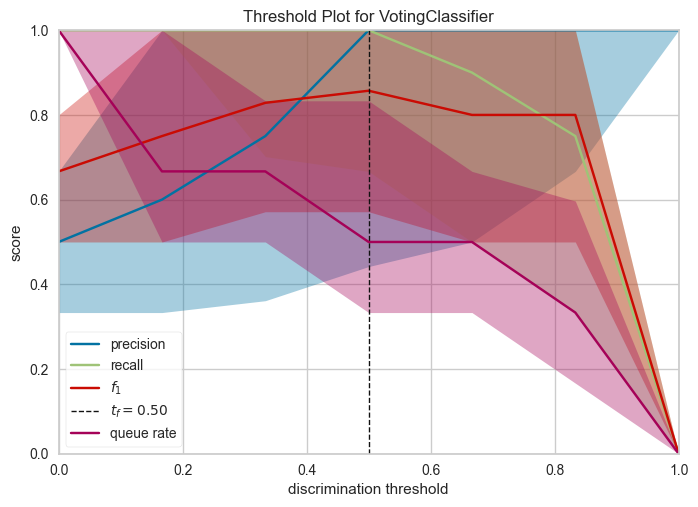

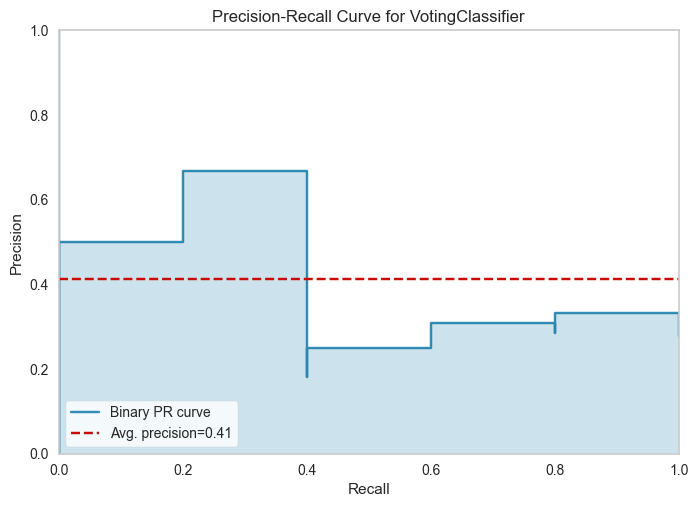

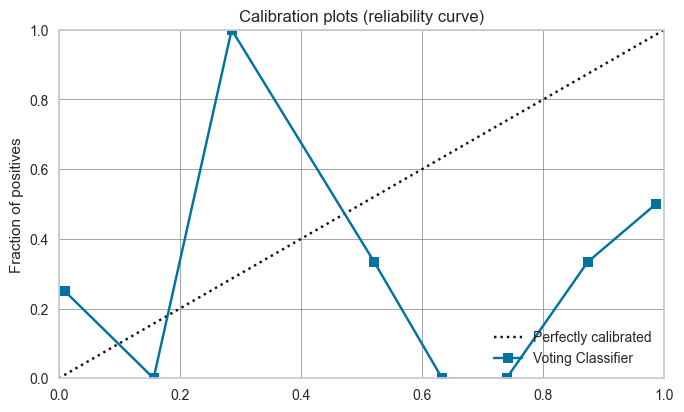

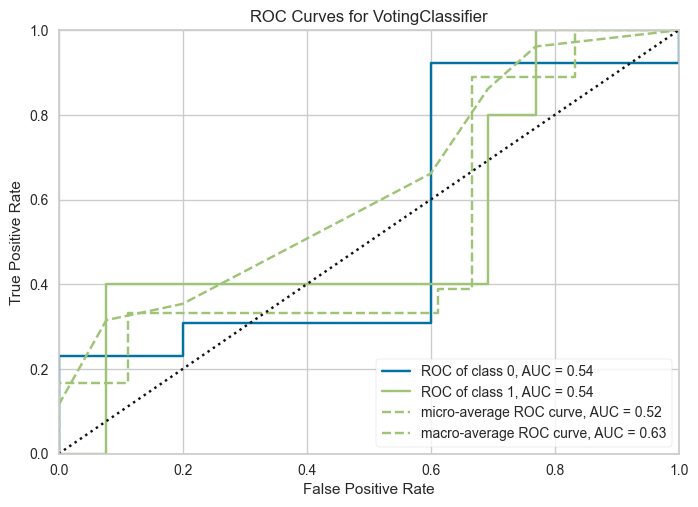

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Age ', 'BMI', 'Tumor size',
                                              'Tumor size.1', 'Tumor size.2',
                                              'Tumor volume', 'Last BMI on file',
                                              'Pre-op visual impairment (y/n) - '
                                              'symptomatic complaint of visual '
                                              'loss',
                                              'Pre-op hydrocephalus (y/n)',
                                              'Pre-op intacranial pressure '
                                              'symptoms',
                                              'Pre-op headache',
                                              'Pre-op endoc...
                 ('actual_estimator',
                  VotingClassifier(estima

In [17]:
import pandas as pd
from pycaret.classification import (
    setup, create_model, tune_model, calibrate_model,
    blend_models, compare_models, finalize_model, save_model, pull
)

# --- Build the modeling table exactly as before ---
df = pd.read_csv("data.csv")
features_permdi = [
    "Age ", "BMI", "Tumor size", "Tumor size.1", "Tumor size.2", "Tumor volume",
    "Last BMI on file",
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss",
    "Pre-op hydrocephalus (y/n)", "Pre-op intacranial pressure symptoms",
    "Pre-op headache", "Pre-op endocrine changes (y/n)",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional",
    "Intraventricular extension",
    "Surgical Approach", "Resection outcome (total, subtotal, partial)", "prior radiation", "BRAF+"
]
target = "Recurrence after this operation"

data = df[features_permdi + [target]].dropna(subset=[target]).copy()
folds = max(2, min(3, int(data[target].value_counts().min())))

_ = setup(
    data=data,
    target=target,
    session_id=42,
    fold=folds,
    fold_strategy="stratifiedkfold",
    fix_imbalance=True,
    verbose=False
)

# Base learners
nb = create_model("nb")                     # strong precision
et   = create_model("catboost")                  # strong recall
# Optional tuning (often helps catboost a bit)
et_t = tune_model(et, optimize="F1")

# Calibrate ridge (gives reliable proba for blending / ROC)
nb_cal = calibrate_model(nb, method="isotonic")  # or "sigmoid"
save_model(nb_cal, "recurrence_nb_calibrated_v1")

# Blend (soft vote on calibrated probabilities)
blend = blend_models(
    estimator_list=[nb_cal, et_t],
    method="soft",          # uses probabilities
    optimize="AUC"          # or "F1" if you care more about positives
)

# See CV metrics of the blend
print(pull().head())

# Threshold tuning (pick operating point)
from pycaret.classification import plot_model
plot_model(blend, plot="threshold")       # interactively pick threshold
plot_model(blend, plot="pr")              # PR curve is informative for rare events
plot_model(blend, plot="calibration")     # check probability calibration
plot_model(blend, plot="auc")

# Finalize & save
blend_final = finalize_model(blend)
save_model(blend_final, "recurrence_blend_nb_et_v1")



In [18]:
print("\n=== NB (base) ===")
nb = create_model("nb")
print(pull())

print("\n=== catboost (base) ===")
et = create_model("catboost")
print(pull())

print("\n=== catboost (tuned) ===")
et_t = tune_model(et, optimize="F1")
print(pull())

print("\n=== NB Calibrated (isotonic) ===")
nb_cal = calibrate_model(nb, method="isotonic")
print(pull())

print("\n=== Blend (NB + catboost) ===")
blend = blend_models([nb_cal, et_t], method="soft", optimize="AUC")
print(pull())



=== NB (base) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.8571,0.8625,0.7500,0.7500,0.7500,0.6500,0.6500
2,0.7692,0.8611,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.7564,0.7912,0.7500,0.5738,0.6406,0.4626,0.4853
Std,0.0880,0.0998,0.2041,0.1429,0.1390,0.1996,0.2102


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.6429  0.6500  0.5000  0.4000  0.4444  0.1860  0.1886
1       0.8571  0.8625  0.7500  0.7500  0.7500  0.6500  0.6500
2       0.7692  0.8611  1.0000  0.5714  0.7273  0.5517  0.6172
Mean    0.7564  0.7912  0.7500  0.5738  0.6406  0.4626  0.4853
Std     0.0880  0.0998  0.2041  0.1429  0.1390  0.1996  0.2102

=== catboost (base) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.5250,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.7143,0.7250,0.5000,0.5000,0.5000,0.3000,0.3000
2,0.7692,0.7222,0.2500,1.0000,0.4000,0.3158,0.4330
Mean,0.7326,0.6574,0.4167,0.6667,0.4667,0.3053,0.3443
Std,0.0259,0.0936,0.1179,0.2357,0.0471,0.0074,0.0627


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.5250  0.5000  0.5000  0.5000  0.3000  0.3000
1       0.7143  0.7250  0.5000  0.5000  0.5000  0.3000  0.3000
2       0.7692  0.7222  0.2500  1.0000  0.4000  0.3158  0.4330
Mean    0.7326  0.6574  0.4167  0.6667  0.4667  0.3053  0.3443
Std     0.0259  0.0936  0.1179  0.2357  0.0471  0.0074  0.0627

=== catboost (tuned) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6500,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
2,0.9231,0.7778,0.7500,1.0000,0.8571,0.8060,0.8216
Mean,0.7601,0.6926,0.5833,0.6333,0.6005,0.4307,0.4367
Std,0.1189,0.0602,0.1179,0.2625,0.1829,0.2694,0.2759


Fitting 3 folds for each of 10 candidates, totalling 30 fits
      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.6500  0.5000  0.5000  0.5000  0.3000  0.3000
1       0.6429  0.6500  0.5000  0.4000  0.4444  0.1860  0.1886
2       0.9231  0.7778  0.7500  1.0000  0.8571  0.8060  0.8216
Mean    0.7601  0.6926  0.5833  0.6333  0.6005  0.4307  0.4367
Std     0.1189  0.0602  0.1179  0.2625  0.1829  0.2694  0.2759

=== NB Calibrated (isotonic) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6750,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.9286,0.8625,0.7500,1.0000,0.8571,0.8108,0.8257
2,0.7692,0.8333,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.8040,0.7903,0.7500,0.6905,0.6948,0.5542,0.5810
Std,0.0909,0.0824,0.2041,0.2208,0.1476,0.2085,0.2161


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.6750  0.5000  0.5000  0.5000  0.3000  0.3000
1       0.9286  0.8625  0.7500  1.0000  0.8571  0.8108  0.8257
2       0.7692  0.8333  1.0000  0.5714  0.7273  0.5517  0.6172
Mean    0.8040  0.7903  0.7500  0.6905  0.6948  0.5542  0.5810
Std     0.0909  0.0824  0.2041  0.2208  0.1476  0.2085  0.2161

=== Blend (NB + catboost) ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6250,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.8571,0.8000,0.5000,1.0000,0.6667,0.5882,0.6455
2,0.9231,0.9167,0.7500,1.0000,0.8571,0.8060,0.8216
Mean,0.8315,0.7806,0.5833,0.8333,0.6746,0.5647,0.5890
Std,0.0871,0.1199,0.1179,0.2357,0.1459,0.2072,0.2166


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.6250  0.5000  0.5000  0.5000  0.3000  0.3000
1       0.8571  0.8000  0.5000  1.0000  0.6667  0.5882  0.6455
2       0.9231  0.9167  0.7500  1.0000  0.8571  0.8060  0.8216
Mean    0.8315  0.7806  0.5833  0.8333  0.6746  0.5647  0.5890
Std     0.0871  0.1199  0.1179  0.2357  0.1459  0.2072  0.2166


In [19]:
from pycaret.classification import stack_models, create_model

# (continue from the same setup; reuse ridge_cal and cat_t)
rf   = create_model("rf")
xgb  = create_model("xgboost")

stack = stack_models(
    estimator_list=[nb_cal, et_t, rf, xgb],
    meta_model=create_model("lr"),   # meta learner
    optimize="AUC"                   # or "F1"
)




,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7857,0.5375,0.5000,0.6667,0.5714,0.4324,0.4404
1,0.7857,0.7250,0.5000,0.6667,0.5714,0.4324,0.4404
2,0.6923,0.7222,0.0000,0.0000,0.0000,0.0000,0.0000
Mean,0.7546,0.6616,0.3333,0.4444,0.3810,0.2883,0.2936
Std,0.0440,0.0877,0.2357,0.3143,0.2694,0.2039,0.2076


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.5714,0.7250,0.2500,0.2500,0.2500,-0.0500,-0.0500
1,0.7143,0.6000,0.5000,0.5000,0.5000,0.3000,0.3000
2,0.6923,0.6389,0.2500,0.5000,0.3333,0.1613,0.1777
Mean,0.6593,0.6546,0.3333,0.4167,0.3611,0.1371,0.1426
Std,0.0628,0.0522,0.1179,0.1179,0.1039,0.1439,0.1450


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.7750,1.0000,0.5000,0.6667,0.4615,0.5477
1,0.6429,0.7000,0.7500,0.4286,0.5455,0.2857,0.3162
2,0.6923,0.6389,0.0000,0.0000,0.0000,0.0000,0.0000
Mean,0.6832,0.7046,0.5833,0.3095,0.4040,0.2491,0.2880
Std,0.0299,0.0557,0.4249,0.2208,0.2900,0.1902,0.2245


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7857,0.5750,0.5000,0.6667,0.5714,0.4324,0.4404
1,0.7857,0.7750,0.5000,0.6667,0.5714,0.4324,0.4404
2,0.7692,0.8889,0.2500,1.0000,0.4000,0.3158,0.4330
Mean,0.7802,0.7463,0.4167,0.7778,0.5143,0.3936,0.4379
Std,0.0078,0.1297,0.1179,0.1571,0.0808,0.0550,0.0035


In [19]:
print(pull().head())
stack_final = finalize_model(stack)

      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7143  0.5750  0.5000  0.5000  0.5000  0.3000  0.3000
1       0.7143  0.7250  0.5000  0.5000  0.5000  0.3000  0.3000
2       0.7692  0.7500  0.2500  1.0000  0.4000  0.3158  0.4330
Mean    0.7326  0.6833  0.4167  0.6667  0.4667  0.3053  0.3443
Std     0.0259  0.0773  0.1179  0.2357  0.0471  0.0074  0.0627


In [20]:
df_original.columns

Index(['Date', 'Age ', 'BMI', 'Surgical Approach',
       'Pre-op visual impairment (y/n) - symptomatic complaint of visual loss',
       'Pre-op hydrocephalus (y/n)', 'Pre-op intacranial pressure symptoms',
       'Pre-op headache', 'Pre-op endocrine changes (y/n)',
       'Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional',
       'Axes disrupted', 'Tumor size', 'Tumor size.1', 'Tumor size.2',
       'Tumor volume', 'Tumor (Adamantinomatous, papillary)', 'BRAF+',
       'Location (purely intrasellar, suprasellar/sellar, suprasellar/sellar with pseudoventricular extension, suprasellar/sellar with intraventricular extension, purely intraventricular)',
       'Intraventricular extension', 'Solid, cystic, mixed',
       'Resection outcome (total, subtotal, partial)', 'Prior operation',
       'recurring tumor?', 'Recurrence after this operation',
       'Recurrence date', 'Days to recurrence',
       'Re-operation after this operation (add date)', 'Time to r